# 06 — Final evaluation closeout viewer (chỉ đọc kết quả đã hoàn tất)

## 1. Protocol và quyết định được khóa trước test

Owner đã duyệt **LR tuned C=2** cho chatbot/API nghiên cứu ngày **2026-10-30**.
LR tuned C=2 là model ứng dụng đã được duyệt trước test. Test không được dùng để chọn lại model hay tối ưu.

Ba ứng viên cố định, theo thứ tự báo cáo:
1. LR baseline: `baseline-v1-f8a5bfdb7b4c12cd`.
2. LR tuned C=2: `tuning-v1-9c4dd013abbba14a`, selected identity `tuned-v1-b8a5602679b3dc5c`.
3. Hard tuned LR+SVC+KNN: `tuned-ensemble-20261029T041701354242Z-6c84dbfe`, dùng lại `hard_vote` và ưu tiên hòa LR → SVC → KNN.

Protocol `final-locked-test-v1`; SHA-256:
`049ee0aa3c2907985c3d3a03ed222b1d6e1efb5921bbbc2d04ec0dea9baa8947`.
Toàn bộ hash/config/identity: [protocol source](../src/models/final_evaluation_protocol.py).
Xem [giao thức đã khai báo](../docs/MODEL_SELECTION_RATIONALE.md#final-locked-test-protocol-2026-10-30).

Test: **28.066 dòng, 25.128 group, 375 feature, 587 label IDs** đúng thứ tự Phase2.
Macro F1 luôn tính đủ 587 nhãn, `zero_division=0`; Accuracy, Macro Precision/Recall, Weighted F1,
coverage và F1=0 là metric phụ. So sánh ghép cặp, chênh correctness theo group có trọng số bằng nhau,
support/per-class và validation–test chỉ mô tả; không chọn lại model hoặc tuning.

Dataset synthetic, cùng vector có thể mang nhãn khác nhau. Phase1 từng EDA toàn CSV:
test được giữ ngoài fit/tuning, chưa phải external blind test. Không suy ra clinical validity hoặc calibrated probability.


## 2. Setup độc lập: mount → source release → session

Chọn Colab kernel; mount Drive bằng command **Colab: Mount Google Drive to Server...** và cell xác thực của extension trước setup. Browser dùng mount được hỗ trợ. Kết nối kernel chưa mount Drive.

Source phải được publish **cả payload** theo [HANDOVER_GUIDE](../docs/HANDOVER_GUIDE.md#không-có-drive-for-desktop), không upload module riêng. Điền SHA-256 từ stage/publish local vào `EXPECTED_RUNTIME_PAYLOAD`. Shared bootstrap kiểm source Drive và copy sang VM; notebook không tự publish/cài gói. Sau reset, chạy setup/import/session/preflight tại đây; không cần chạy notebook 03/04/05.

Run All chỉ kiểm preflight và đọc completed evidence. Không đánh giá lại; gate luôn False và authorization rỗng.

In [9]:
import json, platform, runpy
from pathlib import Path

# Chỉ sửa hai giá trị này; digest lấy từ Windows stage/publish, không lấy từ Drive.
DRIVE_ROOT = Path('/content/drive/MyDrive/ML_Projects/disease-prediction-ml')
EXPECTED_RUNTIME_PAYLOAD = "a3abed4421b95032ec6c5600cc87a0acb1ccde0bab8d0382f45331120a3961c3"
RUNTIME = ROOT = session = prepared = final_result = None
checks = []
step = "Kernel /content"
try:
    if platform.system() != 'Linux' or not Path('/content').is_dir():
        raise RuntimeError("Chọn Colab kernel; notebook này không dùng Python local.")
    checks.append(dict(check=step, status="PASS", detail="Linux /content; bootstrap sẽ xác minh Colab."))
    step = "Drive mount"
    if not Path('/content/drive/MyDrive').is_dir():
        raise FileNotFoundError("Drive chưa mount. Chạy Colab: Mount Google Drive to Server... và cell xác thực do extension tạo, rồi chạy lại setup.")
    checks.append(dict(check=step, status="PASS", detail="MyDrive truy cập được trên kernel hiện tại."))
    step = "Published source"
    entry = DRIVE_ROOT / 'src/data/colab_runtime.py'
    if not entry.is_file():
        raise FileNotFoundError(f"Drive đã mount nhưng thiếu {entry}. Kiểm tài khoản/root và publish toàn payload theo HANDOVER_GUIDE; notebook không tự publish.")
    checks.append(dict(check=step, status="PASS", detail=str(entry)))
    step = "Source release / bootstrap"
    RUNTIME = runpy.run_path(str(entry))['bootstrap_runtime'](
        DRIVE_ROOT, phase=3, expected_payload_sha256=EXPECTED_RUNTIME_PAYLOAD)
    ROOT = RUNTIME.paths.project_root
    checks.append(dict(check=step, status="PASS", detail=f"Windows expected = Drive = VM: {RUNTIME.payload_sha256}"))
except Exception as exc:
    checks.append(dict(check=step, status="FAIL", detail=f"{type(exc).__name__}: {exc}"))
    print(f"BLOCKER [{step}]: {type(exc).__name__}: {exc}")

Stage A PASS | Colab Python 3.13.18 | Drive=/content/drive/MyDrive/ML_Projects/disease-prediction-ml | runtime/Drive read-write OK
Stage B PASS | imports=/content/disease-prediction-ml-runtime | source fingerprint=92b77bb6e4f587fbcc940a2505747ef77b3c263e0557da109b49b1976426bb2e
Runtime payload verified: a3abed4421b95032ec6c5600cc87a0acb1ccde0bab8d0382f45331120a3961c3 | 45 files (source/config/scripts only)


In [10]:
evaluation_api_ready = False
if RUNTIME is None:
    checks.append(dict(check="Final evaluation imports / session", status="SKIPPED", detail="Sửa blocker setup trước; không dùng session từ notebook khác."))
else:
    try:
        from src.models.notebook import ColabTraining
        from src.models.final_evaluation import protocol, digest, preflight, namespace, read_completed, sha256_file, show_result, versions
        from IPython.display import display
        import pandas as pd
        FROZEN = protocol()
        print("Frozen protocol:", FROZEN["protocol_id"], "| SHA-256:", digest(FROZEN))
        display(pd.DataFrame([{"candidate": key} for key in FROZEN["candidates"]]))
        display(pd.DataFrame([{"checkpoint": key, "experiment": value["identity"]["experiment_id"],
                              "pipeline_sha256": value["files"]["pipeline.joblib"]["sha256"],
                              "environment": value["identity"]["versions"]}
                             for key, value in FROZEN["checkpoints"].items()]))
        print("Current environment:", versions())
        print("Frozen voting members:", FROZEN["ensemble"]["members"], "| tie priority:", FROZEN["ensemble"]["priority"])
        session = ColabTraining.open(RUNTIME)
        evaluation_api_ready = True
        checks.append(dict(check="Final evaluation imports / session", status="PASS", detail="Session mới; không load_data, deserialize hoặc predict."))
    except Exception as exc:
        session = None
        checks.append(dict(check="Final evaluation imports / session", status="FAIL", detail=f"{type(exc).__name__}: {exc}"))

Frozen protocol: final-locked-test-v1 | SHA-256: 049ee0aa3c2907985c3d3a03ed222b1d6e1efb5921bbbc2d04ec0dea9baa8947


,candidate
0,lr_baseline
1,lr_tuned_c2
2,hard_tuned_lr_svc_knn


,checkpoint,experiment,pipeline_sha256,environment
0,knn_tuned,tuned-v1-b8a5602679b3dc5c,1d84f44c5d3eec025d7f9fc574fb80eba58b0e38fbb692...,"{'joblib': '1.6.0', 'numpy': '2.1.3', 'python'..."
1,lr_baseline,baseline-v1-f8a5bfdb7b4c12cd,54f124240fd2bb8fb61c39594a55663e1b67f5f5b67595...,"{'joblib': '1.6.0', 'numpy': '2.1.3', 'python'..."
2,lr_tuned_c2,tuned-v1-b8a5602679b3dc5c,4cac3bfd78dfe2849a855130d264c7bebc14d6e8d8e305...,"{'joblib': '1.6.0', 'numpy': '2.1.3', 'python'..."
3,svc_tuned,tuned-v1-b8a5602679b3dc5c,1ac35a1e68225142c6ff60332d8fcf973a57cc0f84c18b...,"{'joblib': '1.6.0', 'numpy': '2.1.3', 'python'..."


Current environment: {'python': '3.13.18', 'sklearn': '1.6.1', 'numpy': '2.1.3', 'scipy': '1.16.3', 'joblib': '1.6.0'}
Frozen voting members: ['logistic_regression', 'linear_svc', 'knn'] | tie priority: ['logistic_regression', 'linear_svc', 'knn', 'bernoulli_nb', 'random_forest']
Stage C PASS | manifest=50308d250d874b1b653a71c31f38dece0ec9fbb4dbc9d94f68bc1461e80b8fe9 | 7 train/validation/metadata checksums OK


,Thông tin,Giá trị
0,Runtime,colab
1,Python,3.13.18
2,Scikit-learn,1.6.1
3,RAM khả dụng (GiB),11.523
4,CPU,Intel(R) Xeon(R) CPU @ 2.20GHz
5,GPU phát hiện,[]
6,Drive đọc/ghi,True


Source workspace: /content/disease-prediction-ml-runtime
Source fingerprint: 92b77bb6e4f587fbcc940a2505747ef77b3c263e0557da109b49b1976426bb2e
Dữ liệu / đầu ra Drive: /content/drive/MyDrive/ML_Projects/disease-prediction-ml
Checksum input hợp lệ; chỉ đọc train/validation, không mở CSV test.


## 3. Preflight chỉ đọc — CHƯA MỞ TEST

Kiểm 7 input train/validation/metadata, source/env, tuning/ensemble manifest và checksum checkpoint.
Không deserialize model, không mở/băm/stat test CSV. Số dòng/group test ở bảng dưới chỉ lấy từ metadata đã khóa.
Shared bootstrap có probes/cache source tạm hiện có; riêng preflight này không ghi storage.


In [11]:
if not evaluation_api_ready:
    checks.append(dict(check="Frozen artifact preflight", status="SKIPPED", detail="Cần setup/import/session thành công."))
else:
    try:
        print("Đang kiểm checksum source/metadata/checkpoint; không deserialize hoặc mở test...", flush=True)
        prepared = preflight(session)
        display(pd.DataFrame(prepared["checkpoints"]))
        display(pd.DataFrame([prepared["test_identity_from_metadata_only"]]))
        print("Preflight:", prepared["status"], "| execution:", prepared["execution_status"])
        print("Test payload opened:", prepared["test_payload_opened"], "| guards:", prepared["guards"])
        checks.append(dict(check="Frozen artifact preflight", status="PASS", detail="Schema/mapping/source/env/manifests/checkpoint hashes; test chỉ từ metadata."))
        if prepared["execution_status"] != "NOT STARTED" and not prepared["execution_status"].startswith("COMPLETED"):
            checks.append(dict(check="One-time execution state", status="FAIL", detail=prepared["execution_status"]))
    except Exception as exc:
        prepared = None
        checks.append(dict(check="Frozen artifact preflight", status="FAIL", detail=f"{type(exc).__name__}: {exc}"))

from IPython.display import Markdown, display

def status_table(rows):
    def clean(value):
        return str(value).replace("|", "/").replace("\n", " ")
    display(Markdown("| Kiểm tra | Trạng thái | Bằng chứng / hành động |\n|---|---|---|\n" +
                     "\n".join("| " + " | ".join(clean(r[k]) for k in ("check", "status", "detail")) + " |" for r in rows)))

status_table(checks)

Đang kiểm checksum source/metadata/checkpoint; không deserialize hoặc mở test...


,checkpoint,status,experiment_id,pipeline_sha256,features
0,knn_tuned,PASS,tuned-v1-b8a5602679b3dc5c,1d84f44c5d3eec025d7f9fc574fb80eba58b0e38fbb692...,375
1,lr_baseline,PASS,baseline-v1-f8a5bfdb7b4c12cd,54f124240fd2bb8fb61c39594a55663e1b67f5f5b67595...,375
2,lr_tuned_c2,PASS,tuned-v1-b8a5602679b3dc5c,4cac3bfd78dfe2849a855130d264c7bebc14d6e8d8e305...,375
3,svc_tuned,PASS,tuned-v1-b8a5602679b3dc5c,1ac35a1e68225142c6ff60332d8fcf973a57cc0f84c18b...,375


,bytes,classes,features,groups,records,relative,sha256
0,292558,587,375,25128,28066,data/processed/test.csv.gz,d71a040a6ead853931cfc75452e456906e5277a3081dc9...


Preflight: PASS | execution: NOT STARTED
Test payload opened: False | guards: {'model_or_feature_fit_attempts': 0, 'test_payload_access': 0, 'protected_write_attempts': 0}


| Kiểm tra | Trạng thái | Bằng chứng / hành động |
|---|---|---|
| Kernel /content | PASS | Linux /content; bootstrap sẽ xác minh Colab. |
| Drive mount | PASS | MyDrive truy cập được trên kernel hiện tại. |
| Published source | PASS | /content/drive/MyDrive/ML_Projects/disease-prediction-ml/src/data/colab_runtime.py |
| Source release / bootstrap | PASS | Windows expected = Drive = VM: a3abed4421b95032ec6c5600cc87a0acb1ccde0bab8d0382f45331120a3961c3 |
| Final evaluation imports / session | PASS | Session mới; không load_data, deserialize hoặc predict. |
| Frozen artifact preflight | PASS | Schema/mapping/source/env/manifests/checkpoint hashes; test chỉ từ metadata. |

## 4. Closeout chỉ đọc — KHÔNG THỰC THI LẠI

Gate mặc định False, authorization rỗng. Nếu bật gate, notebook dừng ngay.
Chỉ đọc namespace đã khóa sau preflight PASS và xác minh SHA completed manifest.
Run chưa hoàn tất hoặc thiếu evidence không được tự resume/evaluate.
Không xóa execution marker; không deserialize, fit, predict hoặc mở CSV test.


In [13]:
print("Closeout viewer: chỉ đọc completed evidence; không cấp hoặc in authorization thực thi.")


AUTHORIZE ONE-TIME LOCKED TEST final-locked-test-v1 049ee0aa3c2907985c3d3a03ed222b1d6e1efb5921bbbc2d04ec0dea9baa8947


In [14]:
RUN_FINAL_LOCKED_TEST = False
OWNER_AUTHORIZATION = ""
if RUN_FINAL_LOCKED_TEST:
    raise RuntimeError("Closeout viewer only reads completed results; evaluation is disabled.")

EXPECTED_COMPLETED_MANIFEST_SHA256 = "f1ad195e1e46154d7a29a421e80387bfa76e494f4df771cede240f882d0b754a"
final_result = None
if globals().get("evaluation_api_ready", False) and prepared is not None and not any(r["status"] == "FAIL" for r in checks):
    try:
        completed_folder = namespace(session.paths.storage_root)
        completed_manifest = completed_folder / "manifest.json"
        if not completed_manifest.is_file():
            print("CHƯA CÓ completed results; chỉ preflight, không đánh giá hoặc tạo output.")
        else:
            completed_sha256 = sha256_file(completed_manifest)
            if completed_sha256 != EXPECTED_COMPLETED_MANIFEST_SHA256:
                raise ValueError("Completed manifest SHA-256 differs from approved closeout identity.")
            completed = read_completed(completed_folder)
            final_result = {**completed, "folder": str(completed_folder), "manifest_sha256": completed_sha256}
            checks.append(dict(check="Completed evidence replay", status="PASS", detail="Manifest và file checksums hợp lệ; không mở CSV test."))
    except Exception as exc:
        final_result = None
        checks.append(dict(check="Completed evidence replay", status="FAIL", detail=f"{type(exc).__name__}: {exc}"))
        print("BLOCKED completed evidence:", type(exc).__name__, str(exc))
else:
    print("SKIPPED completed replay: cần setup/preflight PASS; không dùng session hoặc result cũ.")


Predict fitted checkpoint: lr_baseline
  Test: 64/28,066
  Test: 4,160/28,066
  Test: 8,256/28,066
  Test: 12,352/28,066
  Test: 16,448/28,066
  Test: 20,544/28,066
  Test: 24,640/28,066
  Test: 28,066/28,066
Predict fitted checkpoint: lr_tuned_c2
  Test: 64/28,066
  Test: 4,160/28,066
  Test: 8,256/28,066
  Test: 12,352/28,066
  Test: 16,448/28,066
  Test: 20,544/28,066
  Test: 24,640/28,066
  Test: 28,066/28,066
Predict fitted checkpoint: svc_tuned
  Test: 64/28,066
  Test: 4,160/28,066
  Test: 8,256/28,066
  Test: 12,352/28,066
  Test: 16,448/28,066
  Test: 20,544/28,066
  Test: 24,640/28,066
  Test: 28,066/28,066
Predict fitted checkpoint: knn_tuned
  Test: 64/28,066
  Test: 4,160/28,066
  Test: 8,256/28,066
  Test: 12,352/28,066
  Test: 16,448/28,066
  Test: 20,544/28,066
  Test: 24,640/28,066
  Test: 28,066/28,066
COMPLETED final evaluation: /content/drive/MyDrive/ML_Projects/disease-prediction-ml/artifacts/metadata/final_evaluation/049ee0aa3c290798


## 5. Metrics đã lưu và validation–test

Chỉ hiển thị completed evidence đúng checksum; không tính lại metrics hoặc chọn model.
Khi chưa có bundle hoàn tất, dừng ở preflight. Không tạo kết quả thay thế.


In [15]:
if final_result is None:
    print("CHƯA CÓ ĐIỂM TEST — preparation/preflight only.")
else:
    from src.models.final_evaluation import read_completed
    result_folder = Path(final_result["folder"])
    verified = read_completed(result_folder)
    display(pd.read_csv(result_folder / "comparison.csv"))
    print("Missing label IDs:", verified["missing_label_ids"])


,candidate,split,accuracy,classes_f1_zero,macro_f1,macro_precision,macro_recall,predicted_classes,weighted_f1
0,lr_baseline,validation,0.837091,28,0.787808,0.827420,0.779189,560,0.836675
1,lr_baseline,test,0.842692,28,0.795831,0.830471,0.787887,560,0.842834
2,lr_tuned_c2,validation,0.837660,23,0.793154,0.823867,0.792485,566,0.838440
3,lr_tuned_c2,test,0.844082,22,0.808163,0.837073,0.804752,567,0.844947
4,hard_tuned_lr_svc_knn,validation,0.836913,21,0.796517,0.822713,0.798134,567,0.837682
5,hard_tuned_lr_svc_knn,test,0.842835,22,0.805981,0.833223,0.804620,567,0.843603


Missing label IDs: []


## 6. Lỗi ghép cặp, per-class/group và biểu đồ

3 cặp cố định: tuned LR–baseline LR, hard tuned–tuned LR, hard tuned–baseline LR.
Báo rescue/new errors, cả hai đúng/sai, group cải thiện/giảm/không đổi.
Group differences dùng mean correctness trong mỗi group rồi cho các group trọng số bằng nhau;
không gọi đây là Macro F1 theo group, CI hoặc bằng chứng ý nghĩa thống kê.
Support bins cố định: 0, 1, 2–5, 6–20, >20; bảng đầy đủ 587 lớp được lưu, notebook chỉ hiện phần gọn.


,candidate,split,accuracy,classes_f1_zero,macro_f1,macro_precision,macro_recall,predicted_classes,weighted_f1
0,lr_baseline,validation,0.837091,28,0.787808,0.827420,0.779189,560,0.836675
1,lr_baseline,test,0.842692,28,0.795831,0.830471,0.787887,560,0.842834
2,lr_tuned_c2,validation,0.837660,23,0.793154,0.823867,0.792485,566,0.838440
3,lr_tuned_c2,test,0.844082,22,0.808163,0.837073,0.804752,567,0.844947
4,hard_tuned_lr_svc_knn,validation,0.836913,21,0.796517,0.822713,0.798134,567,0.837682
5,hard_tuned_lr_svc_knn,test,0.842835,22,0.805981,0.833223,0.804620,567,0.843603


,reference,candidate,both_correct,both_wrong,rescues,new_errors,equal_group_accuracy_reference,equal_group_accuracy_candidate,equal_group_delta,groups_improved,groups_worsened,groups_equal
0,lr_baseline,lr_tuned_c2,23534,4259,156,117,0.905789,0.907451,0.001662,100,61,24967
1,lr_tuned_c2,hard_tuned_lr_svc_knn,23499,4220,156,191,0.907451,0.906423,-0.001027,71,106,24951
2,lr_baseline,hard_tuned_lr_svc_knn,23398,4158,257,253,0.905789,0.906423,0.000634,146,142,24840


,classes,records
support_bin,,
1,41,41
2-5,96,323
6-20,127,1480
>20,323,26222


,class_id,disease,test_support,test_independent_groups,support_bin,lr_baseline_precision,lr_baseline_recall,lr_baseline_f1,lr_tuned_c2_precision,lr_tuned_c2_recall,lr_tuned_c2_f1,hard_tuned_lr_svc_knn_precision,hard_tuned_lr_svc_knn_recall,hard_tuned_lr_svc_knn_f1
0,0,abdominal aortic aneurysm,5,5,2-5,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000
1,1,abdominal hernia,29,29,>20,0.903226,0.965517,0.933333,0.903226,0.965517,0.933333,0.964286,0.931034,0.947368
2,2,abscess of nose,25,25,>20,0.875000,0.560000,0.682927,0.888889,0.640000,0.744186,0.888889,0.640000,0.744186
3,3,abscess of the pharynx,20,20,6-20,0.857143,0.900000,0.878049,0.857143,0.900000,0.878049,0.894737,0.850000,0.871795
4,4,acariasis,1,1,1,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000
5,5,achalasia,5,5,2-5,1.000000,0.400000,0.571429,1.000000,0.400000,0.571429,1.000000,0.400000,0.571429
6,6,acne,53,53,>20,0.600000,0.849057,0.703125,0.600000,0.849057,0.703125,0.600000,0.849057,0.703125
7,7,actinic keratosis,117,117,>20,0.880435,0.692308,0.775120,0.880435,0.692308,0.775120,0.880435,0.692308,0.775120
8,8,acute bronchiolitis,199,199,>20,0.958115,0.919598,0.938462,0.963158,0.919598,0.940874,0.958115,0.919598,0.938462
9,9,acute bronchitis,192,192,>20,0.912162,0.703125,0.794118,0.910959,0.692708,0.786982,0.916667,0.687500,0.785714


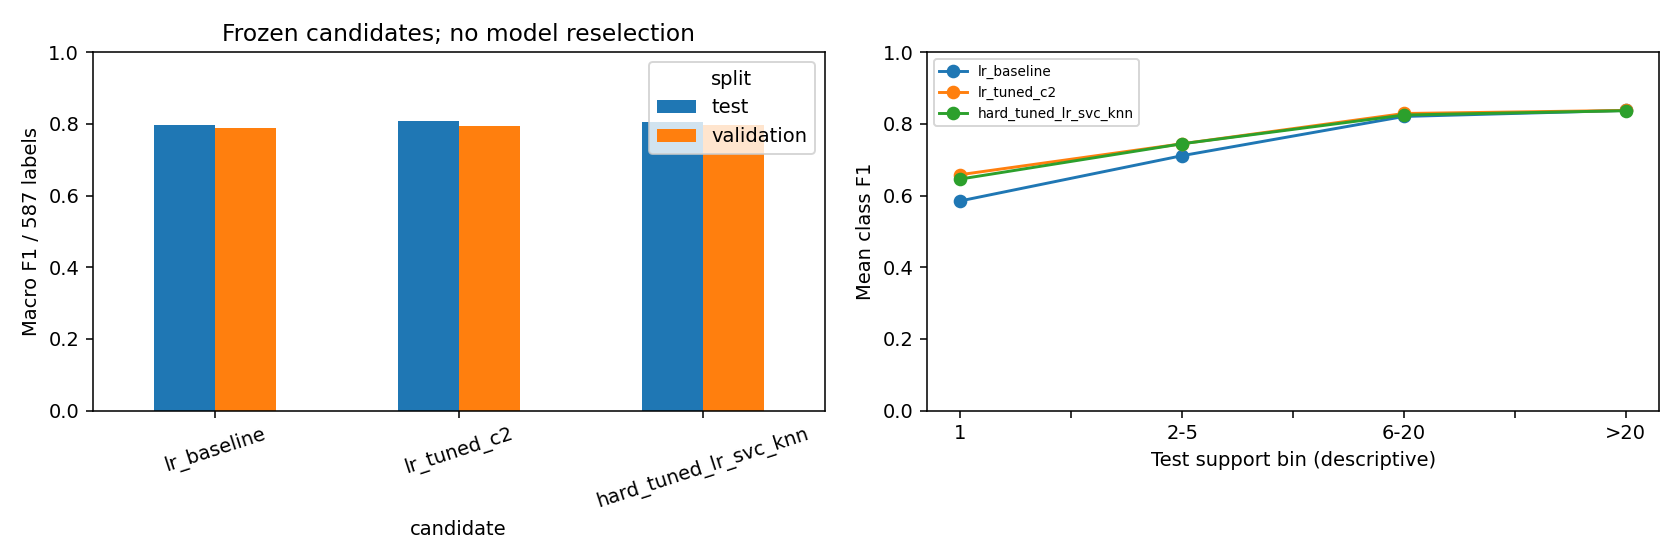

# Final locked-test evaluation

Deployment fixed BEFORE test: LR tuned C=2. No selection from test.

candidate,split,accuracy,classes_f1_zero,macro_f1,macro_precision,macro_recall,predicted_classes,weighted_f1
lr_baseline,validation,0.8370910384068279,28,0.7878081402467481,0.8274197939731976,0.7791885208694249,560,0.836675385063782
lr_baseline,test,0.8426922254685384,28,0.7958306745796887,0.8304710522444024,0.7878866151893594,560,0.8428343938933989
lr_tuned_c2,validation,0.8376600284495022,23,0.7931543818638241,0.8238666389449272,0.7924848742690451,566,0.838439717113135
lr_tuned_c2,test,0.8440818071688163,22,0.808163486172862,0.8370725901054068,0.8047515247665102,567,0.8449466206008978
hard_tuned_lr_svc_knn,validation,0.8369132290184922,21,0.7965170720239344,0.8227126480439321,0.7981336562721902,567,0.8376817578041393
hard_tuned_lr_svc_knn,test,0.842834746668567,22,0.8059813671672197,0.8332232904614251,0.8046199889724036,567,0.84360287513484

Paired transitions (candidate vs reference):
reference,candidate,both_correct,both_wrong,rescues,new_errors,equal_group_accuracy_reference,equal_group_accuracy_candidate,equal_group_delta,groups_improved,groups_worsened,groups_equal
lr_baseline,lr_tuned_c2,23534,4259,156,117,0.9057887899667986,0.907450551588565,0.0016617616217663974,100,61,24967
lr_tuned_c2,hard_tuned_lr_svc_knn,23499,4220,156,191,0.907450551588565,0.9064231452423908,-0.0010274063461742542,71,106,24951
lr_baseline,hard_tuned_lr_svc_knn,23398,4158,257,253,0.9057887899667986,0.9064231452423908,0.0006343552755921426,146,142,24840

Equal-group differences are descriptive, not significance tests. Synthetic dataset; conflicting labels may share symptom vectors. Phase1 inspected the whole raw CSV. Held out from fitting/tuning, not a pristine blind external test. No clinical validation, calibrated probabilities or measured LLM-input generalization. Deployment remains LR tuned C=2 regardless of scores.


In [16]:
if final_result is None:
    print("SKIPPED: chưa có final-test results để phân tích hoặc vẽ.")
else:
    show_result(final_result)

## 7. Manifest và kết luận

Output riêng tại `artifacts/metadata/final_evaluation/<protocol_sha256[:16]>/` trên Drive.
`manifest.json` được tạo cuối cùng; có `execution.json` nhưng thiếu manifest nghĩa là started/partial,
không phải kết quả hoàn tất. Có thể dùng `read_completed(folder)` để kiểm/đọc kết quả đã lưu mà không mở lại CSV test.

Giữ nguyên LR tuned C=2 là deployment đã duyệt bất kể điểm test; hard tuned là đối chứng validation mạnh nhất,
baseline là mốc gốc. Không suy diễn clinical validity, chất lượng extraction LLM hay latency production.
Dừng sau đánh giá và báo cáo; không Gemini, API/frontend hoặc tối ưu thêm.


In [17]:
if final_result is None:
    preflight_result = {
        "status": "PASS" if prepared is not None and not any(r["status"] == "FAIL" for r in checks) else "FAIL",
        "checks": checks,
        "runtime_payload_sha256": RUNTIME.payload_sha256 if RUNTIME else None,
        "protocol_sha256": prepared["protocol_sha256"] if prepared else None,
        "execution_gate": RUN_FINAL_LOCKED_TEST,
        "test_payload_opened": False,
        "checkpoint_deserialized": False,
        "models_trained": 0,
    }
    print(json.dumps(preflight_result, ensure_ascii=False, indent=2))
    print("STOP: closeout chỉ đọc; không tự đánh giá, cấp authorization hoặc tạo kết quả.")
else:
    print("Completed manifest SHA-256:", final_result["manifest_sha256"])
    print("Outputs:", final_result["folder"])
    print("Deployment remains LR tuned C=2; no selection from test.")

Completed manifest SHA-256: f1ad195e1e46154d7a29a421e80387bfa76e494f4df771cede240f882d0b754a
Outputs: /content/drive/MyDrive/ML_Projects/disease-prediction-ml/artifacts/metadata/final_evaluation/049ee0aa3c290798
Deployment remains LR tuned C=2; no selection from test.


In [20]:
# Historical diagnostic source; disabled in the read-only closeout viewer.
# from pathlib import Path
# import hashlib, json, platform, sys, warnings
# import numpy as np
# import pandas as pd
# from sklearn.utils.validation import check_is_fitted
# from threadpoolctl import threadpool_limits
# from src.agent.extraction import Catalog
# from src.data.loader import sha256_file
# from src.models.ensemble import phase4_guard, validate_probabilities
# from src.models.final_evaluation import protocol, versions
# from src.models.training import build_pipeline, load_fitted_checkpoint
# 
# # These private globals are only for the isolated Windows diagnostic run.
# # Leave them unset in Colab; they never change the production API's guard.
# reference_mode = globals().get('_LR_REFERENCE_MODE', True)
# SOURCE = Path(ROOT).resolve()
# DRIVE_ROOT = Path(globals().get('_LR_STORAGE_ROOT',
#     '/content/drive/MyDrive/ML_Projects/disease-prediction-ml')).resolve()
# OUTPUT = Path(globals().get('_LR_OUTPUT', '/content/lr-31318-synthetic-reference.json'))
# assert not OUTPUT.exists(), 'Output exists; do not overwrite previous evidence.'
# assert not OUTPUT.resolve().is_relative_to(DRIVE_ROOT), 'Output must be outside storage.'
# frozen = protocol()
# cp, ti = frozen['checkpoints']['lr_tuned_c2'], frozen['tuning']
# identity = cp['identity']
# expected_versions = dict(identity['versions'])
# if not reference_mode:
#     expected_versions['python'] = '3.13.17'
# assert versions() == expected_versions, ('Unexpected environment', versions(), expected_versions)
# assert platform.system() == ('Linux' if reference_mode else 'Windows')
# if reference_mode:
#     import google.colab  # Reject a plain Linux kernel as an original-Colab reference.
# else:
#     assert platform.machine().upper() in ('AMD64', 'X86_64')
# assert ti['experiment_id'] == 'tuning-v1-9c4dd013abbba14a'
# assert identity['experiment_id'] == 'tuned-v1-b8a5602679b3dc5c'
# assert identity['config']['models']['logistic_regression']['C'] == 2
# assert cp['files']['pipeline.joblib']['sha256'] == '4cac3bfd78dfe2849a855130d264c7bebc14d6e8d8e305b15015141663300ac6'
# 
# checked = {}
# def verify(relative, expected, source=False):
#     base = SOURCE if source else DRIVE_ROOT
#     path = (base / relative).resolve()
#     assert path.is_relative_to(base) and path.is_file(), relative
#     actual = sha256_file(path)
#     assert actual == expected['sha256'], ('Checksum mismatch', relative)
#     assert 'bytes' not in expected or path.stat().st_size == expected['bytes'], relative
#     checked[('source:' if source else '') + relative] = actual
#     return path
# 
# cases = [('zero_boundary', []), ('cough_only', ['cough']), ('fever_only', ['fever']),
#     ('cough_fever', ['cough', 'fever']), ('gastro', ['nausea', 'vomiting']),
#     ('headache_fatigue', ['headache', 'fatigue']),
#     ('respiratory', ['cough', 'fever', 'shortness of breath']), ('all_one_boundary', 'ALL')]
# with phase4_guard(DRIVE_ROOT) as guard:
#     for name, value in identity['source_sha256'].items():
#         verify(name, {'sha256': value}, source=True)
#         module = sys.modules.get(name[:-3].replace('/', '.'))
#         assert module is None or Path(module.__file__).resolve() == SOURCE / name, name
#     phase = json.loads(verify('artifacts/metadata/phase2/dataset_manifest.json',
#         {'sha256': frozen['phase2_manifest_sha256']}).read_text(encoding='utf-8-sig'))
#     assert phase['status'] == 'finalized' and phase['test_locked']
#     assert phase['files'] == frozen['phase2_files'] and phase['processed'] == frozen['processed']
#     for name in ('feature_schema.json', 'label_mapping.json'):
#         relative = 'artifacts/metadata/phase2/' + name
#         verify(relative, frozen['phase2_files'][relative])
#     catalog = Catalog.load(SOURCE, DRIVE_ROOT)
#     assert len(catalog.features) == 375 and len(catalog.classes) == 587
#     assert catalog.schema_id == phase['processed']['schema_sha256']
#     tm = json.loads(verify('artifacts/metadata/tuning/' + ti['experiment_id'] + '/manifest.json',
#         {'sha256': ti['manifest_sha256']}).read_text(encoding='utf-8-sig'))
#     assert tm['status'] == 'completed' and tm['experiment_id'] == ti['experiment_id']
#     assert tm['identity'] == identity
#     for name in ('pipeline.joblib', 'fit.json', 'metadata.json'):
#         relative = cp['folder'] + '/' + name
#         if name == 'pipeline.joblib':
#             assert tm['files'][relative] == cp['files'][name]
#         verify(relative, tm['files'][relative])
#     folder = DRIVE_ROOT / cp['folder']
#     fit = json.loads((folder / 'fit.json').read_text())
#     meta = json.loads((folder / 'metadata.json').read_text())
#     assert fit['status'] == 'fitted' and meta['status'] == 'completed'
#     assert fit['identity'] == meta['identity'] == identity
#     assert fit['model'] == meta['model'] == 'logistic_regression'
#     assert fit['n_input_features'] == 375 and fit['n_retained_features'] == 318
#     assert fit['pipeline_sha256'] == meta['pipeline_sha256'] == cp['files']['pipeline.joblib']['sha256']
#     assert meta['fit_metadata_sha256'] == sha256_file(folder / 'fit.json')
#     assert meta['predictions_sha256'] == tm['files'][cp['folder'] + '/validation_predictions.npz']['sha256']
#     # Compare metadata strings only; do not open validation_predictions.npz.
#     with warnings.catch_warnings(record=True) as caught:
#         warnings.simplefilter('always')
#         model = load_fitted_checkpoint(folder, identity, trusted=True)
#     expected = build_pipeline('logistic_regression', identity['config'])
#     assert model.feature_names_in_.tolist() == list(catalog.features)
#     assert np.array_equal(model.classes_, np.arange(587))
#     assert [k for k, _ in model.steps] == [k for k, _ in expected.steps]
#     assert all(type(a) is type(b) and a.get_params(deep=False) == b.get_params(deep=False)
#         for (_, a), (_, b) in zip(model.steps, expected.steps))
#     lr = model.named_steps['estimator']
#     check_is_fitted(lr, attributes=['coef_', 'intercept_', 'classes_', 'n_features_in_'])
#     assert lr.coef_.shape == (587, 318) and lr.intercept_.shape == (587,) and lr.n_features_in_ == 318
#     assert np.isfinite(lr.coef_).all() and np.isfinite(lr.intercept_).all()
#     assert all(p == 'ALL' or set(p) <= set(catalog.features) for _, p in cases)
#     x = pd.DataFrame([[int(p == 'ALL' or f in p) for f in catalog.features] for _, p in cases],
#         columns=catalog.features, dtype='uint8')
#     with threadpool_limits(limits=1):
#         proba = np.asarray(model.predict_proba(x), dtype=np.float64)
#         labels = np.asarray(model.predict(x))
#     validate_probabilities(proba, len(cases), model.classes_, 587)
#     assert np.issubdtype(labels.dtype, np.integer) and labels.shape == (len(cases),)
#     assert np.array_equal(labels, proba.argmax(axis=1))
#     rank = np.argsort(-proba, axis=1, kind='stable')[:, :3]
#     assert not any(guard.values()), guard
#     packet = dict(protocol_id='lr-windows31317-synthetic-v1',
#         status='REFERENCE GENERATED' if reference_mode else 'NOT VERIFIED',
#         kind='original_colab_reference' if reference_mode else 'windows_candidate_probe',
#         versions=versions(), platform=platform.platform(), executable=sys.executable,
#         feature_count=375, class_count=587, retained_features=318,
#         tuning_experiment=ti['experiment_id'], selected_identity=identity['experiment_id'],
#         checkpoint_sha256=cp['files']['pipeline.joblib']['sha256'],
#         schema_sha256=catalog.schema_id, checked=checked,
#         cases=[{'id': n, 'present': p} for n, p in cases],
#         input_sha256=hashlib.sha256(x.to_numpy().tobytes(order='C')).hexdigest(),
#         predict_labels=labels.tolist(), top3_class_ids=rank.tolist(),
#         top3_labels=[[catalog.classes[i] for i in row] for row in rank],
#         predict_proba=proba.tolist(), probability_rtol=1e-10, probability_atol=1e-12,
#         warnings=[type(w.message).__name__ + ': ' + str(w.message) for w in caught],
#         guards=dict(guard), models_fitted=0, dataset_payload_opened=False,
#         independently_compared=False, production_runtime_approved=False)
# raw = json.dumps(packet, ensure_ascii=False, sort_keys=True, separators=(',', ':')).encode()
# with OUTPUT.open('xb') as out:
#     out.write(raw)
# print(json.dumps({'output': str(OUTPUT), 'sha256': hashlib.sha256(raw).hexdigest(),
#     'status': packet['status'], 'versions': packet['versions'], 'cases': len(cases),
#     'checked_artifacts': sum(not k.startswith('source:') for k in checked),
#     'source_pins': sum(k.startswith('source:') for k in checked), 'guards': dict(guard)}, indent=2))
print("Historical diagnostic cell disabled; no prediction, output write or Drive copy.")


AssertionError: Output exists; do not overwrite previous evidence.

In [22]:
# Historical diagnostic source; disabled in the read-only closeout viewer.
# from pathlib import Path
# import shutil
# import hashlib
# 
# src = Path("/content/lr-31318-synthetic-reference.json")
# dst = Path(
#     "/content/drive/MyDrive/ML_Projects/"
#     "lr-31318-synthetic-reference.json"
# )
# 
# assert src.is_file(), "Không tìm thấy JSON trên Colab"
# assert not dst.exists(), "File đích đã tồn tại, không ghi đè"
# 
# shutil.copy2(src, dst)
# 
# assert hashlib.sha256(src.read_bytes()).hexdigest() == \
#        hashlib.sha256(dst.read_bytes()).hexdigest()
# 
# print("Đã lưu:", dst)
# print("SHA-256:", hashlib.sha256(dst.read_bytes()).hexdigest())
print("Historical diagnostic cell disabled; no prediction, output write or Drive copy.")


Đã lưu: /content/drive/MyDrive/ML_Projects/lr-31318-synthetic-reference.json
SHA-256: 5fe06a3637c471403d46cdb87b2e5cce2a742e8fff1c99aa4a6cb7caef53d0dc
